In [1]:
#don't change this cell
import torch
import pandas as pd
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

In [2]:
#don't change this cell
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [3]:
#TODO
FILE_PATH = 'diabetes.csv'

In [10]:
#don't change this cell
column_names = [f"Feature_{i}" for i in range(1, 9)] + ["Diagnosis"]
df = pd.read_csv(FILE_PATH, header=1, names=column_names, usecols=range(0, 9))

# df["Diagnosis"] = df["Diagnosis"].map({"M": 1, "B": 0})

df.describe()

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Diagnosis
count,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000
mean,3.842243,120.859192,69.101695,20.517601,79.903520,31.990482,0.471674,33.219035,0.348110
std,3.370877,31.978468,19.368155,15.954059,115.283105,7.889091,0.331497,11.752296,0.476682
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243500,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,32.000000,32.000000,0.371000,29.000000,0.000000
75%,6.000000,140.000000,80.000000,32.000000,127.500000,36.600000,0.625000,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [23]:
# don't change this cell
X = df.drop(columns=["Diagnosis"]).values
y = df["Diagnosis"].values

X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32).view(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

In [24]:
#TODO
train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=True)

In [62]:
import torch
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, input_size=8, drop_out = 0.2):
        super(MLP, self).__init__()
        
        self.network = nn.Sequential(
            # nn.Linear(input_size, 256),
            # nn.ReLU(),
            # nn.Dropout(drop_out),

            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(drop_out),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(drop_out),
            
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(drop_out),
            
            nn.Linear(32, 16),
            nn.ReLU(),
            
            nn.Linear(16, 1),
            
            nn.Sigmoid()
        )
        
    def forward(self, x):
        return self.network(x)

In [63]:
#TODO
input_size = X_train.shape[1]
model = MLP(input_size).to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=5e-5)
NUM_EPOCHS = 1000

In [64]:
train_accuracy_list= []
test_accuracy_list= []

#TODO
for epoch in range(NUM_EPOCHS):
    model.train()
    total=0
    corrects= 0
    running_loss = 0.0

    for inputs, labels in train_loader:
        inputs= inputs.to(device)
        labels= labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        total += labels.size(0)
        predicted = (outputs > 0.5).float()
        corrects += (predicted == labels).sum().item()

    accuracy= corrects / total
    train_accuracy_list.append(accuracy)
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}, Loss: {(running_loss / len(train_loader)):.4f}, Acurracy= {accuracy:.4f}")

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs= inputs.to(device)
            labels= labels.to(device)
            outputs = model(inputs)
            predicted = (outputs > 0.5).float()
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    accuracy = correct / total
    test_accuracy_list.append(accuracy)
    print(f"Test Accuracy: {accuracy:.4f}", end="\n\n")

Epoch 1/1000, Loss: 0.9830, Acurracy= 0.4029
Test Accuracy: 0.5974

Epoch 2/1000, Loss: 0.7849, Acurracy= 0.5351
Test Accuracy: 0.6299

Epoch 3/1000, Loss: 0.7487, Acurracy= 0.6101
Test Accuracy: 0.6299

Epoch 4/1000, Loss: 0.7490, Acurracy= 0.6134
Test Accuracy: 0.6299

Epoch 5/1000, Loss: 0.7437, Acurracy= 0.6444
Test Accuracy: 0.6299

Epoch 6/1000, Loss: 0.7259, Acurracy= 0.6362
Test Accuracy: 0.6299

Epoch 7/1000, Loss: 0.7152, Acurracy= 0.6330
Test Accuracy: 0.6169

Epoch 8/1000, Loss: 0.6731, Acurracy= 0.6330
Test Accuracy: 0.6169

Epoch 9/1000, Loss: 0.6728, Acurracy= 0.6476
Test Accuracy: 0.6104

Epoch 10/1000, Loss: 0.6786, Acurracy= 0.6085
Test Accuracy: 0.6039

Epoch 11/1000, Loss: 0.6799, Acurracy= 0.6134
Test Accuracy: 0.6039

Epoch 12/1000, Loss: 0.6912, Acurracy= 0.6166
Test Accuracy: 0.6039

Epoch 13/1000, Loss: 0.6704, Acurracy= 0.6297
Test Accuracy: 0.6039

Epoch 14/1000, Loss: 0.6693, Acurracy= 0.5856
Test Accuracy: 0.6039

Epoch 15/1000, Loss: 0.6661, Acurracy= 0.63

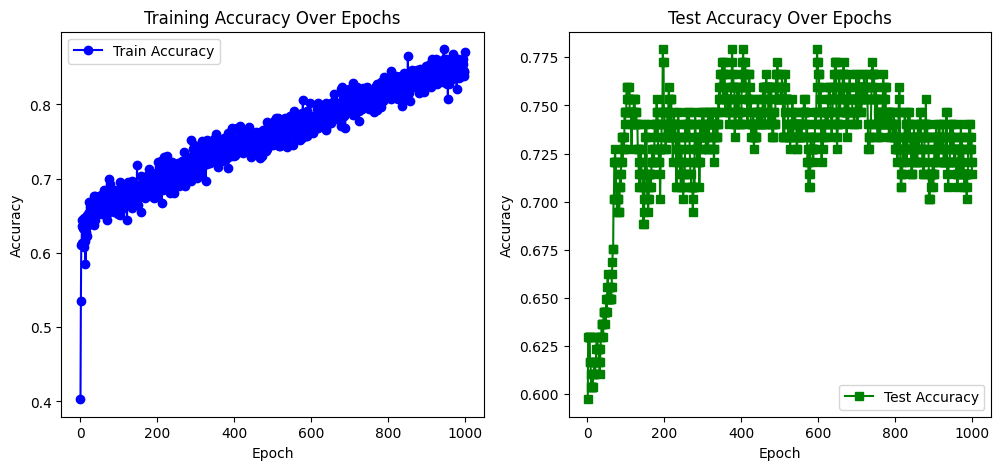

In [65]:

# don't change this cell
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, NUM_EPOCHS+1), train_accuracy_list, marker='o', linestyle='-', color='b', label="Train Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy Over Epochs")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, NUM_EPOCHS+1), test_accuracy_list, marker='s', linestyle='-', color='g', label="Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Test Accuracy Over Epochs")
plt.legend()

plt.show()